In [12]:
import pandas as pd
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score

X_dummy, _ = make_blobs(n_samples=300, centers=4, cluster_std=0.60, random_state=0)
df_manual = pd.DataFrame(X_dummy, columns=['Fitur_1', 'Fitur_2'])

model_kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
label_kmeans = model_kmeans.fit_predict(df_manual)
skor_kmeans = silhouette_score(df_manual, label_kmeans)
print(f"Silhouette Score KMeans (K=4): {skor_kmeans:.4f}")

model_hc = AgglomerativeClustering(n_clusters=4)
label_hc = model_hc.fit_predict(df_manual)
skor_hc = silhouette_score(df_manual, label_hc)
print(f"Silhouette Score Hierarchical (K=4): {skor_hc:.4f}")

Silhouette Score KMeans (K=4): 0.6820
Silhouette Score Hierarchical (K=4): 0.6820


In [13]:
import numpy as np
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

def run_automl_clustering(X, k_range):
    """Fungsi AutoML untuk mem-benchmark algoritma clustering"""
    hasil_benchmark = []
    
    algoritma_dict = {
        'KMeans': KMeans(random_state=42, n_init=10),
        'Hierarchical': AgglomerativeClustering()
    }
    
    for nama_algo, model in algoritma_dict.items():
        for k in k_range:
            model.set_params(n_clusters=k)
            label = model.fit_predict(X)
            
            sil_score = silhouette_score(X, label)
            db_score = davies_bouldin_score(X, label)
            
            hasil_benchmark.append({
                'Algoritma': nama_algo,
                'K_Clusters': k,
                'Silhouette_Score': sil_score,
                'Davies_Bouldin': db_score
            })
            
    df_hasil = pd.DataFrame(hasil_benchmark)
    df_hasil = df_hasil.sort_values(by='Silhouette_Score', ascending=False).reset_index(drop=True)
    
    return df_hasil

leaderboard = run_automl_clustering(df_manual, k_range=range(2, 6))
print(leaderboard)

      Algoritma  K_Clusters  Silhouette_Score  Davies_Bouldin
0        KMeans           4          0.681994        0.437564
1  Hierarchical           4          0.681994        0.437564
2        KMeans           5          0.592388        0.699395
3  Hierarchical           3          0.589773        0.622115
4        KMeans           3          0.589039        0.626272
5  Hierarchical           5          0.587547        0.720270
6  Hierarchical           2          0.547315        0.547345
7        KMeans           2          0.542642        0.561400


In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, calinski_harabasz_score

np.random.seed(42)
data_pelanggan = {
    'Umur': np.random.randint(18, 70, 200),
    'Pendapatan_Juta': np.random.randint(30, 150, 200),
    'Skor_Belanja': np.random.randint(1, 100, 200)
}
df_customer = pd.DataFrame(data_pelanggan)

In [15]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(df_customer)

In [16]:
leaderboard_kasus = []

model_list = [
    ('KMeans', KMeans(random_state=42, n_init=10)),
    ('Agglomerative', AgglomerativeClustering())
]

k_grid = [3, 4, 5, 6]

for nama, model in model_list:
    for k in k_grid:
        model.set_params(n_clusters=k)
        
        label_pred = model.fit_predict(X_scaled)
        
        sil_score = silhouette_score(X_scaled, label_pred)
        ch_score = calinski_harabasz_score(X_scaled, label_pred)

        leaderboard_kasus.append({
            'Model': nama,
            'Jumlah_Segmen (K)': k,
            'Silhouette_Score': np.round(sil_score, 4),
            'CH_Index': np.round(ch_score, 4)
        })

df_leaderboard = pd.DataFrame(leaderboard_kasus)
df_leaderboard = df_leaderboard.sort_values(by='Silhouette_Score', ascending=False).reset_index(drop=True)

print("=== Papan Peringkat (AutoML Benchmarking Leaderboard) ===")
print(df_leaderboard)

=== Papan Peringkat (AutoML Benchmarking Leaderboard) ===
           Model  Jumlah_Segmen (K)  Silhouette_Score  CH_Index
0         KMeans                  6            0.3067   90.3314
1         KMeans                  4            0.2913   85.4112
2         KMeans                  3            0.2805   81.4362
3         KMeans                  5            0.2746   84.0261
4  Agglomerative                  4            0.2475   67.7318
5  Agglomerative                  3            0.2467   66.5013
6  Agglomerative                  6            0.2406   70.3277
7  Agglomerative                  5            0.2307   67.7683


In [17]:
model_terbaik = df_leaderboard.loc[0, 'Model']
k_terbaik = df_leaderboard.loc[0, 'Jumlah_Segmen (K)']

print(f"\nModel Terpilih: {model_terbaik} dengan {k_terbaik} Segmen")

final_model = KMeans(n_clusters=k_terbaik, random_state=42, n_init=10)
df_customer['Segmen_Pelanggan'] = final_model.fit_predict(X_scaled)

profil_segmen = df_customer.groupby('Segmen_Pelanggan').mean().round(2)
print("\n=== Profiling Segmen Pelanggan ===")
print(profil_segmen)


Model Terpilih: KMeans dengan 6 Segmen

=== Profiling Segmen Pelanggan ===
                   Umur  Pendapatan_Juta  Skor_Belanja
Segmen_Pelanggan                                      
0                 39.26           129.43         83.43
1                 30.49            51.78         57.71
2                 59.10           128.26         25.29
3                 28.03           109.75         31.25
4                 52.49            70.89         80.54
5                 54.66            64.94         26.19


/var/folders/q2/2h4p204s56d3vhv_jx5hmc6m0000gn/T/ipykernel_14443/1904711291.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_customer, x='Segmen_Pelanggan', y='Umur', palette='viridis')


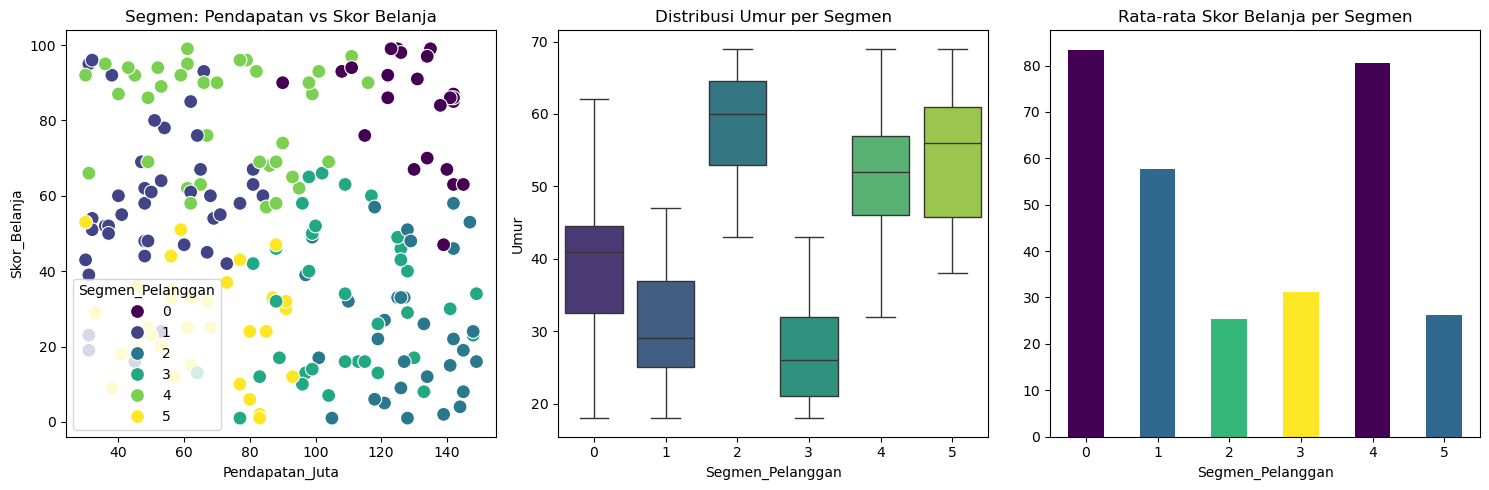

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
sns.scatterplot(data=df_customer, x='Pendapatan_Juta', y='Skor_Belanja', 
                hue='Segmen_Pelanggan', palette='viridis', s=100)
plt.title('Segmen: Pendapatan vs Skor Belanja')

plt.subplot(1, 3, 2)
sns.boxplot(data=df_customer, x='Segmen_Pelanggan', y='Umur', palette='viridis')
plt.title('Distribusi Umur per Segmen')

plt.subplot(1, 3, 3)
profil_segmen['Skor_Belanja'].plot(kind='bar', color=['#440154', '#31688e', '#35b779', '#fde725'])
plt.title('Rata-rata Skor Belanja per Segmen')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

=== 5 Data Teratas ===
               country  child_mort  exports  health  imports  income  \
0          Afghanistan        90.2     10.0    7.58     44.9    1610   
1              Albania        16.6     28.0    6.55     48.6    9930   
2              Algeria        27.3     38.4    4.17     31.4   12900   
3               Angola       119.0     62.3    2.85     42.9    5900   
4  Antigua and Barbuda        10.3     45.5    6.03     58.9   19100   

   inflation  life_expec  total_fer   gdpp  
0       9.44        56.2       5.82    553  
1       4.49        76.3       1.65   4090  
2      16.10        76.5       2.89   4460  
3      22.40        60.1       6.16   3530  
4       1.44        76.8       2.13  12200  


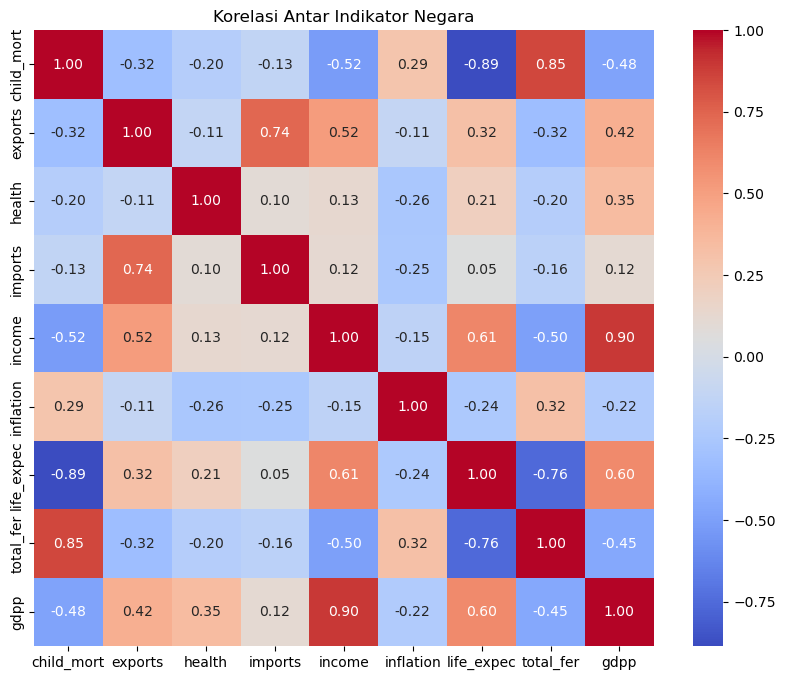


=== Leaderboard Benchmarking ===
           Model  K  Silhouette  DB_Index
0  Agglomerative  2      0.3153    1.3273
1         KMeans  5      0.2993    0.8718
2         KMeans  4      0.2960    1.0530
3         KMeans  2      0.2874    1.3043
4         KMeans  3      0.2833    1.2769
5  Agglomerative  4      0.2481    1.0801
6  Agglomerative  3      0.2456    1.2998
7  Agglomerative  5      0.2193    1.3008

Melakukan Clustering dengan K=2...

=== Profiling Per Cluster ===
         child_mort  exports  health  imports    income  inflation  \
Cluster                                                              
0             12.16     48.6    7.31    49.12  26017.17        5.5   
1             76.28     30.2    6.09    43.64   4227.40       11.1   

         life_expec  total_fer      gdpp  
Cluster                                   
0             76.49       1.94  20507.98  
1             61.91       4.41   1981.24  


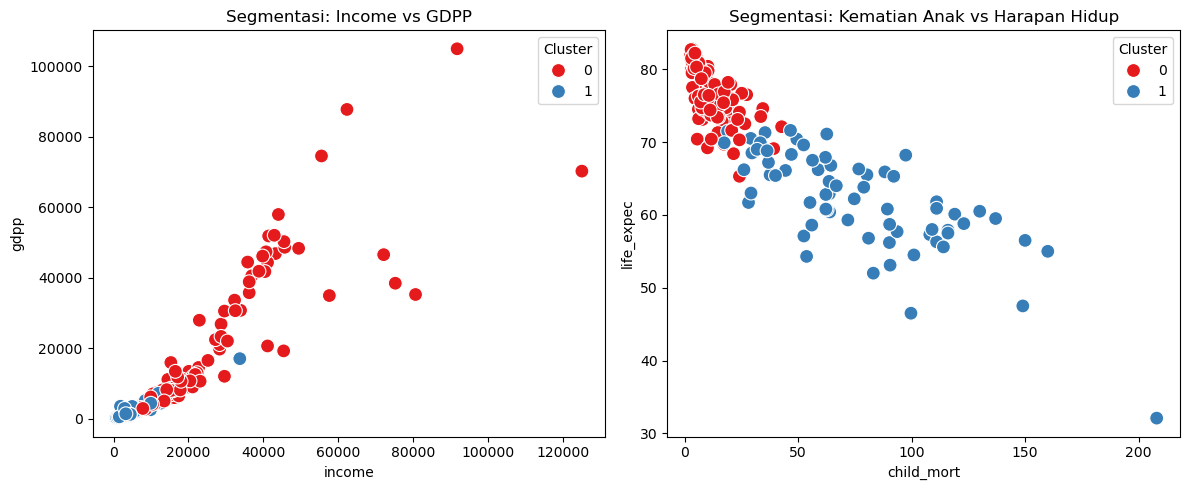


Analisis: Cluster 1 menunjukkan negara-negara dengan tingkat kematian anak tertinggi (76.28)
dan pendapatan terendah (4227.4).
Negara-negara di Cluster 1 memerlukan bantuan pembangunan paling mendesak.


In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

# ==========================================================
# 1. Exploratory Data Analysis (EDA)
# ==========================================================
df = pd.read_csv('country_data.csv')

print("=== 5 Data Teratas ===")
print(df.head())

# Heatmap Korelasi
plt.figure(figsize=(10, 8))
sns.heatmap(df.drop('country', axis=1).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Korelasi Antar Indikator Negara')
plt.show()

# ==========================================================
# 2. Preprocessing
# ==========================================================
X = df.drop('country', axis=1)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# ==========================================================
# 3. AutoML Benchmarking
# ==========================================================
def run_benchmark(data, k_range):
    results = []
    models = [
        ('KMeans', KMeans(random_state=42, n_init=10)),
        ('Agglomerative', AgglomerativeClustering())
    ]
    
    for name, model in models:
        for k in k_range:
            model.set_params(n_clusters=k)
            labels = model.fit_predict(data)
            sil = silhouette_score(data, labels)
            db = davies_bouldin_score(data, labels)
            results.append({
                'Model': name,
                'K': k,
                'Silhouette': np.round(sil, 4),
                'DB_Index': np.round(db, 4)
            })
    return pd.DataFrame(results).sort_values(by='Silhouette', ascending=False).reset_index(drop=True)

leaderboard = run_benchmark(X_scaled, range(2, 6))
print("\n=== Leaderboard Benchmarking ===")
print(leaderboard)

# ==========================================================
# 4. Final Modelling & Profiling
# ==========================================================
# Mengambil K terbaik (biasanya K=3 atau K=2 memberikan silhouette tinggi pada dataset ini)
best_k = leaderboard.loc[0, 'K']
print(f"\nMelakukan Clustering dengan K={best_k}...")

final_model = KMeans(n_clusters=best_k, random_state=42, n_init=10)
df['Cluster'] = final_model.fit_predict(X_scaled)

profiling = df.drop('country', axis=1).groupby('Cluster').mean().round(2)
print("\n=== Profiling Per Cluster ===")
print(profiling)

# ==========================================================
# 5. Visualisasi & Analisis
# ==========================================================
plt.figure(figsize=(12, 5))

# Plot Income vs GDPP
plt.subplot(1, 2, 1)
sns.scatterplot(data=df, x='income', y='gdpp', hue='Cluster', palette='Set1', s=100)
plt.title('Segmentasi: Income vs GDPP')

# Plot Child Mort vs Life Expectancy
plt.subplot(1, 2, 2)
sns.scatterplot(data=df, x='child_mort', y='life_expec', hue='Cluster', palette='Set1', s=100)
plt.title('Segmentasi: Kematian Anak vs Harapan Hidup')

plt.tight_layout()
plt.show()

# Analisis Sederhana
cluster_bantuan = profiling['child_mort'].idxmax()
print(f"\nAnalisis: Cluster {cluster_bantuan} menunjukkan negara-negara dengan tingkat kematian anak tertinggi ({profiling.loc[cluster_bantuan, 'child_mort']})")
print(f"dan pendapatan terendah ({profiling.loc[cluster_bantuan, 'income']}).")
print(f"Negara-negara di Cluster {cluster_bantuan} memerlukan bantuan pembangunan paling mendesak.")
